# Exercise — GW190814: matched filtering in three detectors

**Goal:** Apply the methods learned from the GW150914 to **GW190814** using the local **H1, L1, and V1** strain files.

You will estimate a PSD for each detector, compute matched-filter SNRs, calculate the Allen $\chi^2$ statistic, and construct the reweighted SNR. You may need to use code from your earlier notebook.

**Event time:** GPS $1249852257.0$ (2019-08-14 21:10:39 UTC). The downloaded files cover 256 seconds at 4096 Hz, centred approximately on this time.

**Template starting point:** $m_1\simeq24.4\,M_\odot$, $m_2\simeq2.73\,M_\odot$ (approximate **detector-frame** masses). 

Use zero spins initially and the waveform approximant demonstrated earlier. 

The observed signal has appreciable higher-order-mode contributions, so this simple template is an exercise, **not** a fully optimized parameter-estimation waveform.

**Suggested analysis cutoff:** $f_{\rm{low}}=20$ Hz. Work in a short interval around the trigger when identifying peaks; ignore filtering-corrupted edges.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from pycbc.frame import read_frame
from pycbc.filter import highpass, resample_to_delta_t, matched_filter
from pycbc.psd import welch, interpolate, inverse_spectrum_truncation
from pycbc.waveform import get_td_waveform
from pycbc.vetoes import power_chisq
from pycbc.events.ranking import newsnr

plt.rcParams.update({'figure.figsize': (11, 4), 'font.size': 11})

In [5]:
GPS = 1249852257.0
SAMPLING_FREQ = 2048
DURATION = 256
IFOS = ['H1', 'L1', 'V1']

# Works when launched from either repository root or notebooks/.
DATA_DIR = Path('data') if Path('data').is_dir() else Path('../data')

def load_detector(ifo):
    """Read locally prepared GW190814 GWF and condition the strain."""
    filename = f'GW190814_{ifo}_4096Hz_{DURATION}s.gwf'
    path = DATA_DIR / filename
    channel = f'{ifo}:GWOSC-4KHZ_R1_STRAIN'

    if not path.exists():
        raise FileNotFoundError(f'{path} is missing. Run python download_data.py first.')

    raw = read_frame(str(path), channel)
    strain = resample_to_delta_t(highpass(raw, 15.0), 1.0 / SAMPLING_FREQ)
    return strain.crop(2, 2)


strain = {ifo: load_detector(ifo) for ifo in IFOS}
for ifo in IFOS:
    data = strain[ifo]
    print(f'{ifo}: start={data.start_time}, duration={data.duration}, fs={data.sample_rate}')

H1: start=1249852131.0, duration=252.0, fs=2048.0
L1: start=1249852131.0, duration=252.0, fs=2048.0
V1: start=1249852131.0, duration=252.0, fs=2048.0


## Task 1 — Compute PSDs for H1, L1, and V1

1. Use Welch's method with **4-second segments and 50% overlap** to estimate the noise PSD separately for each detector.
2. Interpolate each PSD to the frequency resolution of its corresponding strain data.
3. Apply inverse-spectrum truncation with a **4-second** impulse-response length and $f_{\rm low}=20$ Hz.
4. Plot the **amplitude spectral densities** ($\sqrt{S_n(f)}$) for all three detectors on one log–log plot.
5. Which detector has the best sensitivity?

**Check:** Why do the three detectors have different ASD curves? Why must each PSD match the frequency resolution of its detector's strain segment?

H1: PSD calculated successfully
L1: PSD calculated successfully
V1: PSD calculated successfully


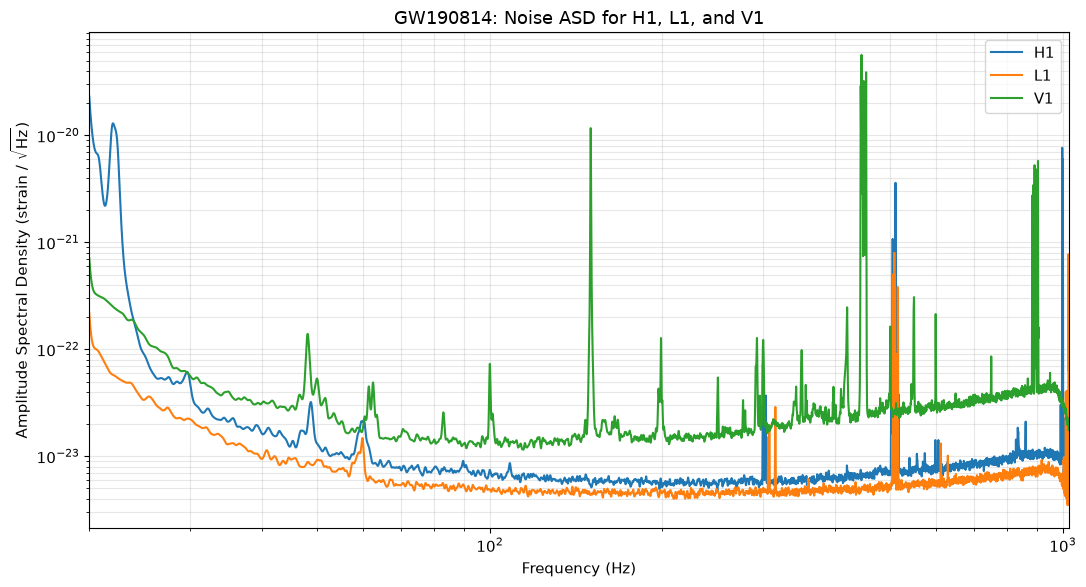

In [6]:

# Task 1 — Compute PSDs for H1, L1, and V1

# Estimate the noise PSD using Welch's method
psd = {}

for ifo in IFOS:
    data = strain[ifo]

    # Welch's method: 4-second segments, 50% overlap
    psd_est = welch(
        data,
        seg_len=4 * SAMPLING_FREQ,
        seg_stride=2 * SAMPLING_FREQ
    )

    # Interpolate PSD to match the strain's frequency resolution
    psd_est = interpolate(psd_est, data.delta_f)

    # Apply inverse-spectrum truncation
    psd_est = inverse_spectrum_truncation(
        psd_est,
        int(4 * SAMPLING_FREQ),
        low_frequency_cutoff=20.0,
        trunc_method='hann'
    )

    psd[ifo] = psd_est

    print(f"{ifo}: PSD calculated successfully")


# Plot the amplitude spectral density (ASD)
plt.figure(figsize=(11, 6))

for ifo in IFOS:
    frequencies = psd[ifo].sample_frequencies
    asd = np.sqrt(psd[ifo])

    # Plot only frequencies at and above 20 Hz
    mask = frequencies >= 20

    plt.loglog(
        frequencies[mask],
        asd[mask],
        label=ifo
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel(r"Amplitude Spectral Density (strain / $\sqrt{\mathrm{Hz}}$)")
plt.title("GW190814: Noise ASD for H1, L1, and V1")
plt.xlim(20, SAMPLING_FREQ / 2)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



## Task 2 — Matched-filter SNR

1. Generate a waveform template using initial detector-frame component masses **$m_1=24.4\,M_\odot$ and $m_2=2.73\,M_\odot$**, zero spins, and $f_{\rm low}=20$ Hz.
2. Resize and cyclically shift the template as demonstrated in the GW150914 notebook to match the strain segment and the matched-filter time convention.
3. Matched-filter **each detector separately**, using its own PSD.
4. Plot $|\rho(t)|$ for H1, L1, and V1 near the expected event time. Record the peak SNR and GPS time for each detector.

**Check:** Do the detector peaks occur at exactly the same time? Why might their SNRs differ? Avoid circular-convolution and PSD-filtering edge regions when looking for peaks.

**Reminder:** A fixed template provides an illustrative result, not necessarily the published search SNR.

H1: Peak SNR = 11.05, GPS time = 1249852257.009766
L1: Peak SNR = 21.50, GPS time = 1249852257.012695
V1: Peak SNR = 4.58, GPS time = 1249852256.996094


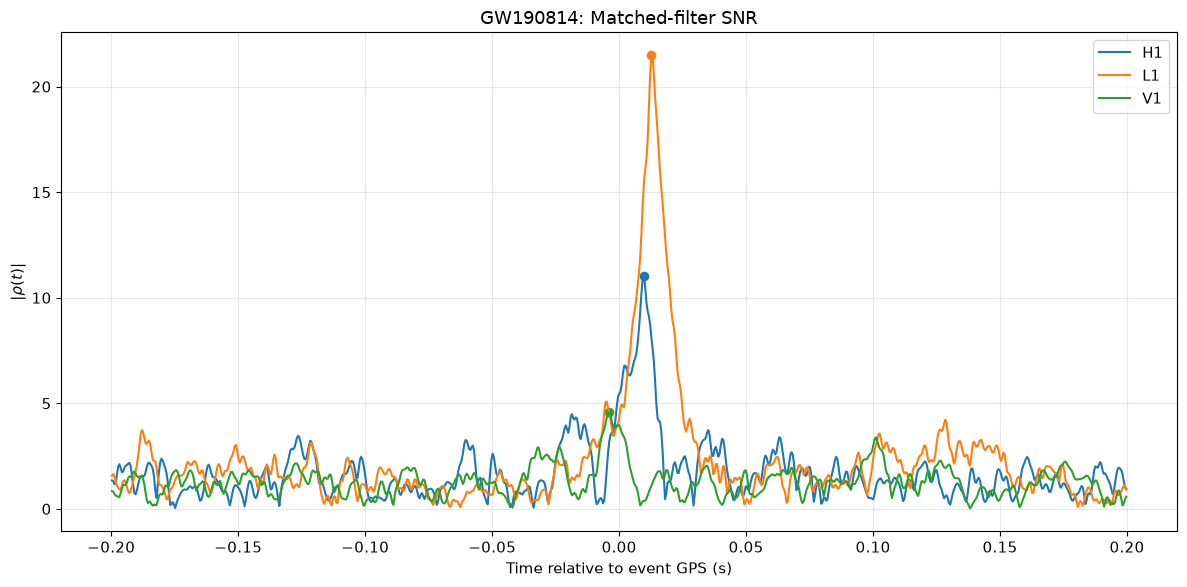


Peak SNR Summary
------------------------------------------
Detector    Peak SNR      GPS time        
H1          11.05         1249852257.009766
L1          21.50         1249852257.012695
V1          4.58          1249852256.996094


In [7]:

# Task 2 — Matched-filter SNR for H1, L1, and V1

from pycbc.waveform import get_td_waveform
from pycbc.filter import matched_filter

M1 = 24.4
M2 = 2.73
F_LOW = 20.0

# Generate the waveform template (zero spins)
hp, hc = get_td_waveform(
    approximant="IMRPhenomD",
    mass1=M1,
    mass2=M2,
    spin1z=0.0,
    spin2z=0.0,
    delta_t=1.0 / SAMPLING_FREQ,
    f_lower=F_LOW
)

# Store SNR time series and peak results
snr_series = {}
peak_results = {}

for ifo in IFOS:
    data = strain[ifo]

    # Resize the template to match the strain length
    template = hp.copy()
    template.resize(len(data))

    # Cyclically shift the template to the matched-filter time convention
    template = template.cyclic_time_shift(template.start_time)

    # Matched filtering using this detector's own PSD
    snr = matched_filter(
        template,
        data,
        psd=psd[ifo],
        low_frequency_cutoff=F_LOW
    )

    # Remove filter-corrupted edges
    snr = snr.crop(4, 4)

    snr_series[ifo] = snr

    # Find the peak near the expected GPS event time
    snr_abs = abs(snr)
    times = snr.sample_times.numpy()
    values = snr_abs.numpy()

    window = np.abs(times - GPS) <= 0.2

    if not np.any(window):
        print(f"{ifo}: No samples found near the event time.")
        continue

    indices = np.where(window)[0]
    peak_idx = indices[np.argmax(values[window])]

    peak_snr = values[peak_idx]
    peak_time = times[peak_idx]

    peak_results[ifo] = (peak_snr, peak_time)

    print(
        f"{ifo}: Peak SNR = {peak_snr:.2f}, "
        f"GPS time = {peak_time:.6f}"
    )


# Plot absolute SNR near GW190814
plt.figure(figsize=(12, 6))

for ifo in IFOS:
    snr = snr_series[ifo]

    times = snr.sample_times.numpy()
    values = abs(snr).numpy()

    # Display a 0.4-second window around the trigger
    window = np.abs(times - GPS) <= 0.2

    plt.plot(
        times[window] - GPS,
        values[window],
        label=ifo
    )

    if ifo in peak_results:
        peak_snr, peak_time = peak_results[ifo]
        plt.scatter(
            peak_time - GPS,
            peak_snr,
            s=35
        )

plt.xlabel("Time relative to event GPS (s)")
plt.ylabel(r"$|\rho(t)|$")
plt.title("GW190814: Matched-filter SNR")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# Summary table
print("\nPeak SNR Summary")
print("-" * 42)
print(f"{'Detector':<12}{'Peak SNR':<14}{'GPS time':<16}")

for ifo in IFOS:
    if ifo in peak_results:
        peak_snr, peak_time = peak_results[ifo]
        print(f"{ifo:<12}{peak_snr:<14.2f}{peak_time:<16.6f}")


## Task 3 — Allen $\chi^2$ signal-consistency test

1. Use PyCBC's `power_chisq` with the **same template and detector-specific PSD** used above.
2. Choose a suitable number of frequency bins, for example **$p=16$**, and calculate the reduced statistic

$$\chi_r^2=\frac{\chi^2}{2p-2}.$$

3. Evaluate $\chi_r^2$ at the matched-filter peak found in **each detector**.
4. Plot $\chi_r^2(t)$ near the event.

**Check:** Is $\chi_r^2$ close to 1 in every detector? What could cause departures (noise, imperfect template, higher modes, etc.)?

## Task 4 — Reweighted SNR

1. Use `newsnr` to compute the reweighted SNR from $|\rho|$ and $\chi_r^2$.
2. Plot the ordinary SNR and reweighted SNR in a window near GW190814 for all three detectors.
3. Compare the peak values and summarize the results in a small table.

**Check:** When does $\chi^2$ penalize the SNR? Why can a genuine signal have $\chi_r^2$ noticeably different from 1 for a simplified template?

## Discussion questions

1. Which detector provides the clearest evidence for GW190814? Is this determined by sensitivity alone?
2. What differences do you observe between this asymmetric-mass event and GW150914?
3. Why would a real search use a **bank of templates**, rather than just one template?

**References:** [GWOSC GW190814 event page](https://gwosc.org/eventapi/html/O3_Discovery_Papers/GW190814/v1/)